In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!unzip -q -o /content/drive/MyDrive/tlp25_IRP/npy_files.zip -d /content/

In [3]:
#!ls /content/content/drive/MyDrive/tlp25_IRP/npy_files


In [4]:
!pip install pandas==2.3.3 livelossplot torchinfo -q

import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import glob
import sys
import pandas as pd
from sklearn.model_selection import train_test_split
from torchinfo import summary
import random
from sklearn.metrics import r2_score
from torch.utils.data import DataLoader
import torch.nn as nn
from livelossplot import PlotLosses

sys.path.append("/content/drive/MyDrive/tlp25_IRP/Modelling")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 147.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 626.0/626.0 kB 54.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 136.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.1/86.1 kB 10.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires ipython==7.34.0, but you have ipython 9.16.0 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.


In [5]:
sys.path.append("/content/drive/MyDrive/tlp25_IRP/Modelling")

from UNET import UNET
from Plot_dataset import plot_dataset
from get_norm_stats import get_normalization_stats
from UHSDataset_new import UHSDataset, transform_dataset

In [6]:
def set_device(device="cpu", idx=0):
    if device != "cpu":
        if torch.cuda.device_count() > idx and torch.cuda.is_available():
            print("Cuda installed! Running on GPU {} {}!".format(idx, torch.cuda.get_device_name(idx)))
            device="cuda:{}".format(idx)
        elif torch.cuda.device_count() > 0 and torch.cuda.is_available():
            print("Cuda installed but only {} GPU(s) available! Running on GPU 0 {}!".format(torch.cuda.device_count(), torch.cuda.get_device_name()))
            device="cuda:0"
        else:
            device="cpu"
            print("No GPU available! Running on CPU")
    return device

device = set_device("cuda")

def set_seed(seed=42):
    """
    Set the random seed for reproducibility.

    Parameters:
    ----------
    seed (int): The seed value to set for random number generation.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.enabled = True

    return True

Cuda installed! Running on GPU 0 NVIDIA A100-SXM4-40GB!


In [67]:
npy_file_dir = "/content/content/drive/MyDrive/tlp25_IRP/npy_files/"

site_dirs = sorted(os.listdir(npy_file_dir))

train_files, val_test_files = train_test_split(site_dirs, test_size=0.3, random_state=42)
val_files, test_files = train_test_split(val_test_files, test_size = 0.5, random_state=42)

In [8]:
print(train_files)

['Site_462', 'Site_685', 'Site_463', 'Site_900', 'Site_584', 'Site_166', 'Site_446', 'Site_285', 'Site_458', 'Site_98', 'Site_78', 'Site_1006', 'Site_4', 'Site_236', 'Site_965', 'Site_132', 'Site_604', 'Site_537', 'Site_656', 'Site_275', 'Site_547', 'Site_25', 'Site_946', 'Site_438', 'Site_524', 'Site_264', 'Site_883', 'Site_618', 'Site_824', 'Site_219', 'Site_959', 'Site_901', 'Site_441', 'Site_536', 'Site_596', 'Site_410', 'Site_768', 'Site_1004', 'Site_2', 'Site_931', 'Site_260', 'Site_356', 'Site_540', 'Site_479', 'Site_807', 'Site_647', 'Site_827', 'Site_616', 'Site_958', 'Site_923', 'Site_738', 'Site_571', 'Site_726', 'Site_740', 'Site_701', 'Site_206', 'Site_265', 'Site_431', 'Site_879', 'Site_250', 'Site_796', 'Site_130', 'Site_193', 'Site_331', 'Site_739', 'Site_402', 'Site_55', 'Site_583', 'Site_1037', 'Site_471', 'Site_18', 'Site_590', 'Site_34', 'Site_510', 'Site_644', 'Site_521', 'Site_817', 'Site_872', 'Site_1', 'Site_969', 'Site_403', 'Site_344', 'Site_74', 'Site_915', '

In [ ]:
stats_dict = get_normalization_stats(train_dataset=train_files)

In [57]:
!ls content/drive/MyDrive/tlp25_IRP/

npy_files


In [70]:
import pickle
with open('/content/drive/MyDrive/tlp25_IRP/norm_stats.pkl', 'wb') as f:
    pickle.dump(stats_dict, f)

In [95]:
transform = transform_dataset
dir = '/content/content/drive/MyDrive/tlp25_IRP/npy_files/'
train_dataset = UHSDataset2(train_files, transform=transform, norm_stats=stats_dict, dir=dir)
val_dataset = UHSDataset2(val_files, transform=transform, norm_stats=stats_dict, dir=dir)
test_dataset = UHSDataset2(test_files, transform=transform, norm_stats=stats_dict, dir=dir)

In [45]:
!ls content/drive/MyDrive/tlp25_IRP/npy_files/norm_stats*

ls: cannot access 'content/drive/MyDrive/tlp25_IRP/npy_files/norm_stats*': No such file or directory


In [74]:
%timeit train_dataset[0]
%timeit train_dataset[949]

19.4 ms ± 185 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)
19.4 ms ± 217 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [36]:
model=UNET(in_channels=3, out_channels=5).to(device)
output = model(torch.ones(1, 3, 12, 61, 61).to(device))
summary(model, input_size=(1, 3, 12, 61, 61))

Layer (type:depth-idx)                   Output Shape              Param #
UNET                                     [1, 5, 12, 61, 61]        --
├─Encoder: 1-1                           [1, 32, 16, 64, 64]       --
│    └─ConvBlock: 2-1                    [1, 32, 16, 64, 64]       --
│    │    └─Conv3d: 3-1                  [1, 32, 16, 64, 64]       2,624
│    │    └─BatchNorm3d: 3-2             [1, 32, 16, 64, 64]       64
│    │    └─GELU: 3-3                    [1, 32, 16, 64, 64]       --
│    └─ConvBlock: 2-2                    [1, 32, 16, 64, 64]       --
│    │    └─Conv3d: 3-4                  [1, 32, 16, 64, 64]       27,680
│    │    └─BatchNorm3d: 3-5             [1, 32, 16, 64, 64]       64
│    │    └─GELU: 3-6                    [1, 32, 16, 64, 64]       --
│    └─MaxPool3d: 2-3                    [1, 32, 8, 32, 32]        --
├─Encoder: 1-2                           [1, 64, 8, 32, 32]        --
│    └─ConvBlock: 2-4                    [1, 64, 8, 32, 32]        --
│    │  

In [96]:
set_seed(42)
p = 0.6
lr = 1e-3
batch_size = 32
num_workers = 4
wd = 1e-6
epochs = 100
mseloss = nn.MSELoss()
optimiser = torch.optim.Adam(params=model.parameters(), lr=lr, weight_decay=wd)

# small_train_dataset = train_files[:8]
# small_dataset = UHSDataset(small_train_dataset, transform=transform)
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=True)
valid_loader = DataLoader(dataset=val_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)



In [76]:
def loss_function(output, target):
  output.

def train(model, optimizer, criterion, data_loader):
    model.train()
    train_loss = 0.
    for input, target in data_loader:
        input, target = input.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(input)
        loss = criterion(output, target)
        loss.backward()
        train_loss += loss*input.size(0)
        optimizer.step()
    train_loss = train_loss / len(data_loader.dataset)
    return train_loss

def valid(model, criterion, data_loader):
    model.eval()
    valid_loss = 0.
    with torch.no_grad():
        for input, target in data_loader:
            input, target = input.to(device), target.to(device)
            output = model(input) #5, 12, 61, 61
            loss = criterion(output, target)
            valid_loss += loss*input.size(0)
        valid_loss = valid_loss / len(data_loader.dataset)
        return valid_loss

def test(model, data_loader):
    model.eval()
    targets = []
    outputs = []
    with torch.no_grad():
        for input, target in data_loader:
            input, target = input.to(device), target.to(device)
            output = model(input)
            targets.append(target)
            outputs.append(output)
        return torch.cat(targets), torch.cat(outputs)

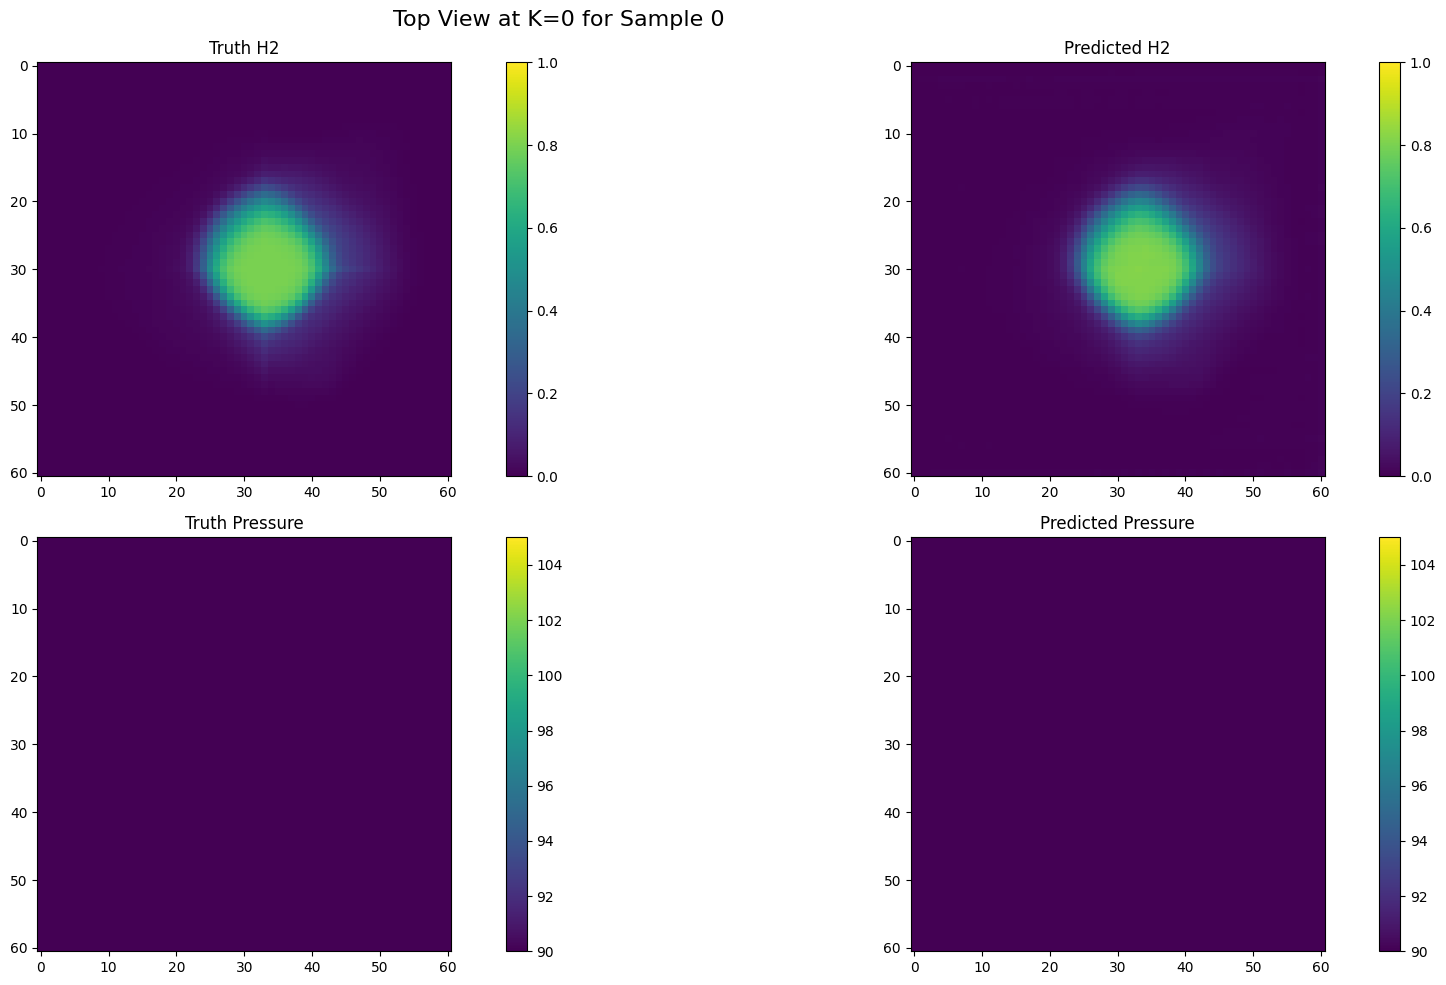

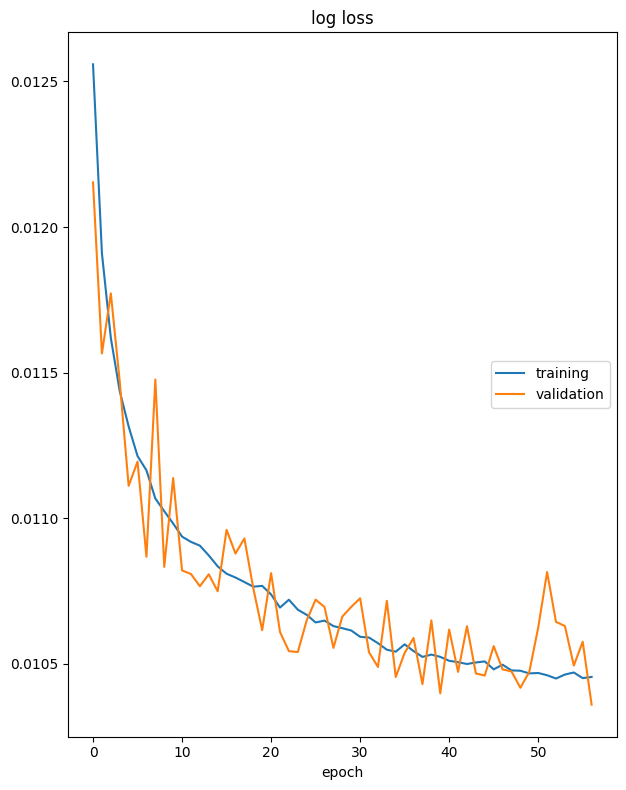

log loss
	training         	 (min:    0.010, max:    0.013, cur:    0.010)
	validation       	 (min:    0.010, max:    0.012, cur:    0.010)


KeyboardInterrupt: 

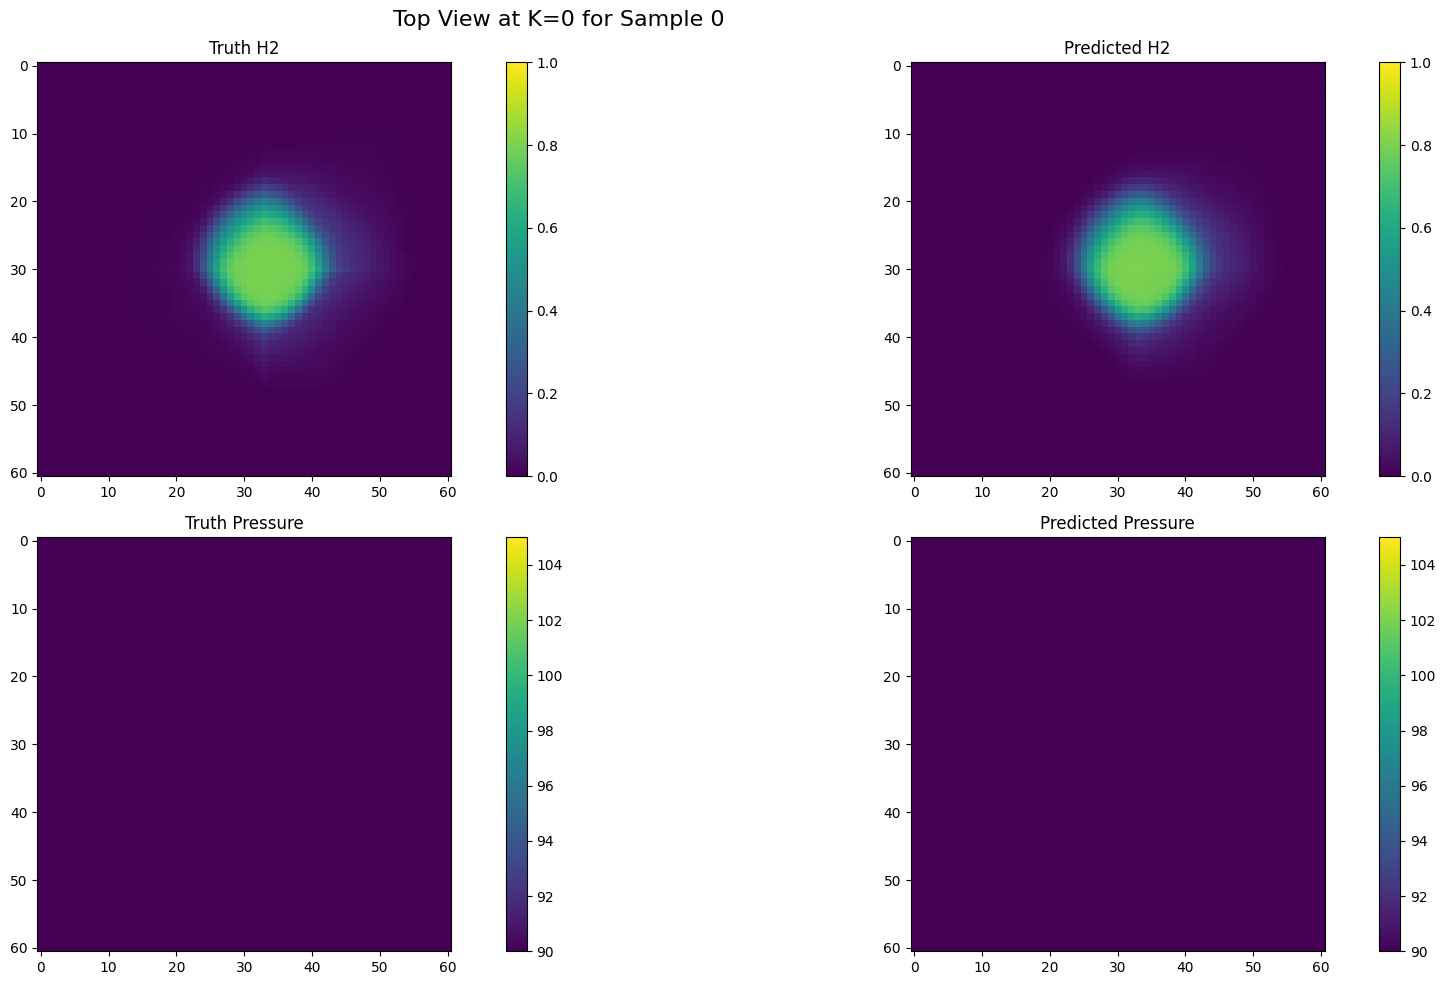

In [79]:
liveloss = PlotLosses()

for i in range(epochs):
  train_loss = train(model, optimiser, mseloss, train_loader)
  valid_loss = valid(model, mseloss, valid_loader)

  logs ={}
  logs["" + "log loss"] = train_loss.item()
  logs["val_" + "log loss"] = valid_loss.item()
  liveloss.update(logs)
  liveloss.send()

  rand_int = torch.randint(0, len(val_dataset), (1,)).item()
  valid_sample, val_target = val_dataset[rand_int]
  with torch.no_grad():
    output_sample = model(valid_sample.unsqueeze(0).to(device))
  output_sample = output_sample.squeeze(0).cpu()
  plot_dataset(val_target, output_sample, view='top', position=0, index=0, prediction=True)

  # y_true_list = []
  # y_pred_list = []

  # for x, y in valid_loader:
  #     with torch.no_grad():
  #         pred = model(x.to(device))
  #     y_true_list.append(y)
  #     y_pred_list.append(pred)

  # y_true = torch.cat(y_true_list, dim=0)
  # y_pred = torch.cat(y_pred_list, dim=0)

  # y_true = y_true.cpu().numpy()
  # y_pred = y_pred.cpu().numpy()

  # if i % 10 == 0 or i == 1:
  #   for c in range(5):
  #     yt = y_true[:, c].reshape(-1)
  #     yp = y_pred[:, c].reshape(-1)
  #     print(r2_score(yt, yp))

  if i % 10 == 0:
     model_save_name = f'UNET_epoch_{i}.pth'           # .pt and .pth are common file extensions for saving models in pytorch
     path = f"/content/drive/My Drive/tlp25_IRP/Modelling/{model_save_name}" # use this to store in your Google Drive storage
     torch.save(model.state_dict(), path)


In [80]:
i = 'final_full_set'

model_save_name = f'UNET_epoch_{i}.pth'           # .pt and .pth are common file extensions for saving models in pytorch
path = f"/content/drive/My Drive/tlp25_IRP/Modelling/{model_save_name}" # use this to store in your Google Drive storage
torch.save(model.state_dict(), path)

In [97]:
from sklearn.metrics import r2_score

model.eval()

def get_predictions(model, loader, device):
    y_true_list = []
    y_pred_list = []
    model.eval()
    with torch.no_grad():
      for x, y in loader:
          pred = model(x.to(device))
          y_true_list.append(y.cpu())
          y_pred_list.append(pred.cpu())
    y_true = torch.cat(y_true_list, dim=0).numpy()
    y_pred = torch.cat(y_pred_list, dim=0).numpy()
    return y_true, y_pred

y_true, y_pred = get_predictions(model, valid_loader, device)
#y_true, y_pred = get_predictions(model, valid_loader_debug, device)

def r2_per_channel(y_true, y_pred, channel_names=None):
    n_channels = y_true.shape[1]
    results = {}
    for c, name in enumerate(channel_names):
        yt = y_true[:, c].reshape(-1)
        yp = y_pred[:, c].reshape(-1)
        yt_plume = yt > 0
        yp = y_predict >0
        results[name] = r2_score(yt, yp)
    return results

channel_names = ['H2 Saturation', 'Pressure', 'FCMIR', 'FCMPR', 'FCMIP']
scores = r2_per_channel(y_true, y_pred, channel_names)
for name, score in scores.items():
    print(f"{name}: {score:.4f}")

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7be5fc46a020>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7be5fc46a020>self._shutdown_workers()Exception ignored in: 
Traceback (most recent call last):

<function _MultiProcessingDataLoaderIter.__del__ at 0x7be5fc46a020>Exception ignored in:   File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    Traceback (most recent call last):
self._shutdown_workers()      File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
if w.is_alive():

     <function _MultiProcessingDataLoaderIter.__del__ at 0x7be5fc46a020>  File "/usr/local/lib/python3

H2 Saturation: 0.9979
Pressure: 0.9745
FCMIR: 0.7772
FCMPR: 0.3668
FCMIP: 0.9762
